## Import Packages

In [1]:
import os
import joblib
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly

from sklearn import set_config
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate, StratifiedKFold, train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.impute import KNNImputer
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

from sklearn.metrics import (
    roc_auc_score, recall_score, accuracy_score, f1_score, precision_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, precision_recall_curve,
)

from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline as ImbPipeline
import optuna

optuna.logging.set_verbosity(optuna.logging.WARNING)
warnings.filterwarnings("ignore")
set_config(transform_output="pandas")

print("All libraries imported successfully.")

All libraries imported successfully.


d:\Churn modelling\churn_venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
from dotenv import load_dotenv
load_dotenv()

True

In [3]:
import dagshub
import mlflow

DAGSHUB_USER_TOKEN = os.getenv("DAGSHUB_USER_TOKEN")

try:
    dagshub.init(repo_owner='Ankitkumar1141', repo_name='Churn-modelling', mlflow=True)
    mlflow.set_tracking_uri('https://dagshub.com/Ankitkumar1141/Churn-modelling.mlflow')
    mlflow.set_experiment('Experiment 9 - Final Champion Model')
    print('MLflow tracking active on DagsHub.')
except Exception as e:
    print(f"[MLflow Notice] {e}")

Accessing as Ankitkumar1141

Initialized MLflow to track repo "Ankitkumar1141/Churn-modelling"

Repository Ankitkumar1141/Churn-modelling initialized!

2026/11/11 21:18:01 INFO mlflow.tracking.fluent: Experiment with name 'Experiment 9 - Final Champion Model' does not exist. Creating a new experiment.


MLflow tracking active on DagsHub.


In [4]:
df = pd.read_csv("preprocessed.csv")
print("Loaded dataset shape:", df.shape)
df.head(3)

Loaded dataset shape: (10000, 37)


,customer_id,name,gender,age,salary,location_id,churned,account_id,tenure,balance,...,is_single_product,inactive_senior,engagement_score,high_risk_inactive,is_female,geo_france,geo_germany,geo_spain,geo_uk,geo_usa
0,15634602,Hargrave,female,42,101348.88,2,1,A15634602SID,2,NaN,...,1,0,0.750000,0,1,1,0,0,0,0
1,15647311,Hill,female,41,112542.58,6,0,A15647311SID,1,83807.86,...,1,0,0.416667,0,1,0,0,0,0,1
2,15619304,Onio,female,42,113931.57,4,1,A15619304SID,8,159660.80,...,0,0,0.583333,0,1,0,0,0,1,0


## Exploratory Checks

In [5]:
df.dtypes

customer_id                  int64
name                        object
gender                      object
age                          int64
salary                     float64
location_id                  int64
churned                      int64
account_id                  object
tenure                       int64
balance                    float64
num_products                 int64
has_credit_card              int64
is_active                    int64
geography                   object
age_group                   object
salary_bracket              object
tenure_group                object
has_balance                  int64
churn_label                 object
has_credit_card_label       object
is_active_label             object
balance_to_salary          float64
balance_per_product        float64
age_when_joined              int64
products_per_tenure        float64
is_senior_risk               int64
is_extreme_product_risk      int64
is_single_product            int64
inactive_senior     

In [6]:
df.isna().sum().sort_values(ascending=False).head(5)

balance        3617
name              0
gender            0
age               0
customer_id       0
dtype: int64

In [7]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [8]:
print(df["churned"].value_counts())
churn_rate = df["churned"].mean()
print("\nChurn rate: {:.2%}".format(churn_rate))

churned
0    7963
1    2037
Name: count, dtype: int64

Churn rate: 20.37%


## Drop Unnecessary Columns

In [9]:
# Drop columns identified in prior notebooks as non-predictive or redundant
drop_columns = [
    "has_balance",
    "products_per_tenure",
    "has_credit_card",
    "geo_france", "geo_uk", "geo_usa", "geo_spain", "geo_germany",
    "tenure", "salary",
    "customer_id",
    "account_id", "name", "location_id",
    "age_when_joined", "age",
    "churn_label",
    "has_credit_card_label",
    "is_active_label",
]

df = df.drop(columns=drop_columns)
print("Shape after dropping columns:", df.shape)
df.head(3)

Shape after dropping columns: (10000, 18)


,gender,churned,balance,num_products,is_active,geography,age_group,salary_bracket,tenure_group,balance_to_salary,balance_per_product,is_senior_risk,is_extreme_product_risk,is_single_product,inactive_senior,engagement_score,high_risk_inactive,is_female
0,female,1,NaN,1,1,france,36-45,high,new (0-2),0.000000,0.000000,0,0,1,0,0.750000,0,1
1,female,0,83807.86,1,1,usa,36-45,high,new (0-2),0.744670,83807.860000,0,0,1,0,0.416667,0,1
2,female,1,159660.80,3,0,uk,36-45,high,veteran (8-10),1.401362,53220.266667,0,1,0,0,0.583333,0,1


In [10]:
missing_cols = df.isna().any(axis=0).loc[lambda x: x].index.tolist()
print("Columns with missing values:", missing_cols)

Columns with missing values: ['balance']


In [11]:
pct_missing_rows = df.isna().any(axis=1).mean().round(4) * 100
n_missing = df.isna().any(axis=1).sum()
print(f"Rows with missing values: {pct_missing_rows:.2f}%  ({n_missing:,} rows)")

Rows with missing values: 36.17%  (3,617 rows)


## Train / Test Split

In [12]:
X = df.drop(columns="churned")
y = df["churned"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

print("Train size : {:,}  |  churn rate: {:.2%}".format(X_train.shape[0], y_train.mean()))
print("Test  size : {:,}  |  churn rate: {:.2%}".format(X_test.shape[0], y_test.mean()))

Train size : 8,000  |  churn rate: 20.38%
Test  size : 2,000  |  churn rate: 20.35%


In [13]:
print("Train shape:", X_train.shape)
print("Test  shape:", X_test.shape)
missing_in_train = X_train.isna().sum()
print("Missing in train (balance only):\n", missing_in_train[missing_in_train > 0])

Train shape: (8000, 17)
Test  shape: (2000, 17)
Missing in train (balance only):
 balance    2891
dtype: int64


## Column Type Identification

In [14]:
numeric_cols     = X.select_dtypes(include=["number"]).columns.tolist()
categorical_cols = X.select_dtypes(include=["object", "category", "string"]).columns.tolist()
binary_cols      = [c for c in numeric_cols if X[c].nunique() == 2]
scale_cols       = [c for c in numeric_cols if c not in binary_cols]

print("Numeric (to scale) :", scale_cols)
print("Binary pass-thru   :", binary_cols)
print("Categorical OHE    :", categorical_cols)

Numeric (to scale) : ['balance', 'num_products', 'balance_to_salary', 'balance_per_product', 'engagement_score']
Binary pass-thru   : ['is_active', 'is_senior_risk', 'is_extreme_product_risk', 'is_single_product', 'inactive_senior', 'high_risk_inactive', 'is_female']
Categorical OHE    : ['gender', 'geography', 'age_group', 'salary_bracket', 'tenure_group']


## Preprocessing Pipeline

In [15]:
preprocessor = ColumnTransformer(
    transformers=[
        ("scale",          MinMaxScaler(), scale_cols),
        ("nominal_encode", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), categorical_cols),
    ],
    remainder="passthrough",
    verbose_feature_names_out=False,
)
preprocessor.set_output(transform="pandas")

knn_imputer = KNNImputer(n_neighbors=10)

In [16]:
base_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("knn_imputer",  knn_imputer),
])

X_train_trans = base_pipeline.fit_transform(X_train)
X_test_trans  = base_pipeline.transform(X_test)

print("X_train transformed shape:", X_train_trans.shape)
print("X_test  transformed shape:", X_test_trans.shape)

X_train transformed shape: (8000, 28)
X_test  transformed shape: (2000, 28)


In [17]:
sampler = RandomUnderSampler(random_state=42)
X_train_resampled, y_train_resampled = sampler.fit_resample(X_train_trans, y_train)

print("Before resampling — Train shape:", X_train_trans.shape)
print("After  resampling — Train shape:", X_train_resampled.shape)
print("Class distribution after resampling:")
print(y_train_resampled.value_counts())

Before resampling — Train shape: (8000, 28)
After  resampling — Train shape: (3260, 28)
Class distribution after resampling:
churned
0    1630
1    1630
Name: count, dtype: int64


## Champion Model Selection & Final Training

In [18]:
# Winner architecture parameters
champion_params = {
    "n_estimators": 271,
    "max_depth": 8,
    "learning_rate": 0.0253,
    "subsample": 0.8117,
    "colsample_bytree": 0.5525,
    "min_child_weight": 3,
    "gamma": 4.8089,
    "reg_alpha": 0.0068,
    "random_state": 42,
    "n_jobs": -1,
    "verbosity": 0,
    "eval_metric": "logloss",
}

champion_model = XGBClassifier(**champion_params)
champion_model.fit(X_train_resampled, y_train_resampled)
print("Champion model trained on resampled training data.")

Champion model trained on resampled training data.


## Model Diagnostics & Evaluation

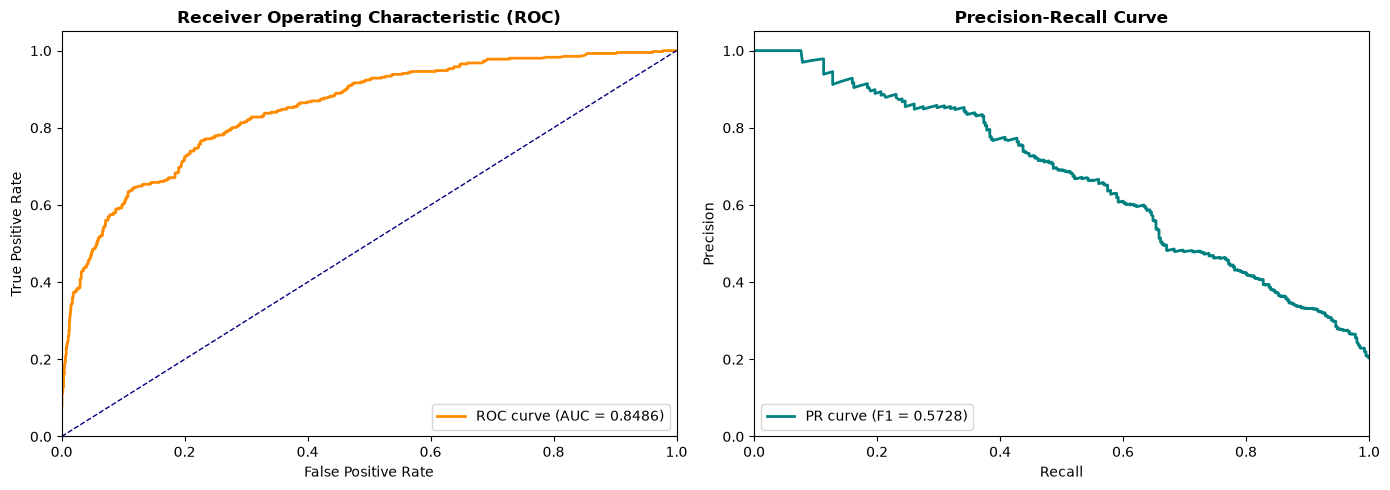

In [19]:
# Held-out Test Set Predictions & Probabilities
y_pred = champion_model.predict(X_test_trans)
y_prob = champion_model.predict_proba(X_test_trans)[:, 1]

fpr, tpr, roc_thresholds = roc_curve(y_test, y_prob)
precision, recall, pr_thresholds = precision_recall_curve(y_test, y_prob)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ROC Curve
axes[0].plot(fpr, tpr, color="darkorange", lw=2, label=f"ROC curve (AUC = {roc_auc_score(y_test, y_prob):.4f})")
axes[0].plot([0, 1], [0, 1], color="navy", lw=1, linestyle="--")
axes[0].set_xlim([0.0, 1.0])
axes[0].set_ylim([0.0, 1.05])
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("Receiver Operating Characteristic (ROC)", fontweight="bold")
axes[0].legend(loc="lower right")

# Precision-Recall Curve
axes[1].plot(recall, precision, color="teal", lw=2, label=f"PR curve (F1 = {f1_score(y_test, y_pred):.4f})")
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall Curve", fontweight="bold")
axes[1].legend(loc="lower left")

plt.tight_layout()
plt.show()

## Optimal Threshold Business Analysis

In [20]:
# Business Decision: Threshold Tuning for Churn Retention
# Default threshold is 0.50. Let's analyze recall vs precision across thresholds.
thresholds = np.linspace(0.2, 0.8, 13)
thresh_results = []

for t in thresholds:
    y_pred_t = (y_prob >= t).astype(int)
    rec  = recall_score(y_test, y_pred_t)
    prec = precision_score(y_test, y_pred_t, zero_division=0)
    f1   = f1_score(y_test, y_pred_t, zero_division=0)
    acc  = accuracy_score(y_test, y_pred_t)
    thresh_results.append({
        "Threshold": round(t, 2),
        "Recall": round(rec, 4),
        "Precision": round(prec, 4),
        "F1": round(f1, 4),
        "Accuracy": round(acc, 4),
    })

pd.DataFrame(thresh_results)

,Threshold,Recall,Precision,F1,Accuracy
0,0.20,0.9681,0.2682,0.4200,0.4560
1,0.25,0.9459,0.2955,0.4503,0.5300
2,0.30,0.9263,0.3198,0.4754,0.5840
3,0.35,0.8821,0.3403,0.4911,0.6280
4,0.40,0.8378,0.3871,0.5295,0.6970
5,0.45,0.7862,0.4318,0.5575,0.7460
6,0.50,0.7494,0.4635,0.5728,0.7725
7,0.55,0.6708,0.4964,0.5705,0.7945
8,0.60,0.6486,0.5593,0.6007,0.8245
9,0.65,0.5897,0.6202,0.6045,0.8430


## Model & Pipeline Artifact Serialization

In [22]:
from pathlib import Path

In [23]:
# Serialize artifacts for production API deployment
models_dir = Path("../models")
models_dir.mkdir(exist_ok=True, parents=True)

# 1. Fitted ColumnTransformer preprocessor
joblib.dump(preprocessor, models_dir / "preprocessor.joblib")
print("Saved:", models_dir / "preprocessor.joblib")

# 2. Fitted KNN Imputer
joblib.dump(knn_imputer, models_dir / "knn_imputer.joblib")
print("Saved:", models_dir / "knn_imputer.joblib")

# 3. Fitted Resampler (for documentation/offline retraining)
joblib.dump(sampler, models_dir / "resampler.joblib")
print("Saved:", models_dir / "resampler.joblib")

# 4. Final trained champion model
joblib.dump(champion_model, models_dir / "model.joblib")
print("Saved:", models_dir / "model.joblib")

# 5. Full End-to-End Inference Pipeline
# At inference time, pipeline takes raw X dataframe -> transforms -> predicts probability
inference_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("knn_imputer",  knn_imputer),
    ("model",        champion_model),
])

joblib.dump(inference_pipeline, models_dir / "inference_pipeline.joblib")
print("Saved:", models_dir / "inference_pipeline.joblib")
print("\nAll production artifacts successfully serialized.")

Saved: ..\models\preprocessor.joblib
Saved: ..\models\knn_imputer.joblib
Saved: ..\models\resampler.joblib
Saved: ..\models\model.joblib
Saved: ..\models\inference_pipeline.joblib

All production artifacts successfully serialized.


## Test Serialized End-to-End Pipeline

In [24]:
# Test the serialized inference pipeline on a raw test sample
loaded_pipeline = joblib.load(models_dir / "inference_pipeline.joblib")
sample_raw = X_test.head(5)

sample_preds  = loaded_pipeline.predict(sample_raw)
sample_probas = loaded_pipeline.predict_proba(sample_raw)[:, 1]

pd.DataFrame({
    "Actual": y_test.head(5).values,
    "Predicted": sample_preds,
    "Probability": sample_probas.round(4)
})

,Actual,Predicted,Probability
0,0,0,0.1170
1,0,0,0.2069
2,0,0,0.1680
3,0,0,0.2001
4,0,0,0.2934


## MLflow Registry & Lifecycle Promotion

In [25]:
try:
    with mlflow.start_run(run_name="Champion Final Model"):
        mlflow.log_params(champion_params)
        mlflow.log_metric("final_test_roc_auc", roc_auc_score(y_test, y_prob))
        mlflow.log_metric("final_test_recall", recall_score(y_test, y_pred))
        mlflow.log_metric("final_test_precision", precision_score(y_test, y_pred))
        mlflow.log_metric("final_test_f1", f1_score(y_test, y_pred))
        mlflow.log_metric("final_test_accuracy", accuracy_score(y_test, y_pred))

        # Infer signature
        signature = mlflow.models.infer_signature(
            model_input=X_test.head(10),
            model_output=loaded_pipeline.predict_proba(X_test.head(10))[:, 1]
        )

        mlflow.sklearn.log_model(
            sk_model=loaded_pipeline,
            artifact_path="champion_churn_model",
            registered_model_name="CustomerChurnChampion",
            signature=signature,
        )
        print("Model successfully logged and registered in MLflow Model Registry.")
except Exception as e:
    print(f"[MLflow Notice] {e}")

2026/11/11 21:24:38 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


🏃 View run Champion Final Model at: https://dagshub.com/Ankitkumar1141/Churn-modelling.mlflow/#/experiments/8/runs/4effe937eef4440396f6c9565df74c9d
🧪 View experiment at: https://dagshub.com/Ankitkumar1141/Churn-modelling.mlflow/#/experiments/8
[MLflow Notice] The saved sklearn model references untrusted types. If you are sure loading these types is safe, set the 'skops_trusted_types' parameter when calling 'log_model' or 'save_model' to the list of trusted types. Root error: Untrusted types found in the file: ['xgboost.core.Booster', 'xgboost.sklearn.XGBClassifier'].
